In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [3]:
from sklearn.metrics import (
    mean_squared_error,
    root_mean_squared_error,
    r2_score
)

In [4]:
df=pd.read_csv('Student_Performance_Multiple_linear_regression.csv')
df.head(10)

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0
5,3,78,No,9,6,61.0
6,7,73,Yes,5,6,63.0
7,8,45,Yes,4,6,42.0
8,5,77,No,8,2,61.0
9,4,89,No,4,0,69.0


In [8]:
df = pd.get_dummies(df,columns=["Extracurricular Activities"],drop_first=True,dtype=int)

In [9]:
df.head()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index,Extracurricular Activities_Yes
0,7,99,9,1,91.0,1
1,4,82,4,2,65.0,0
2,8,51,7,2,45.0,1
3,5,52,5,2,36.0,1
4,7,75,8,5,66.0,0


In [10]:
X = df.drop("Performance Index", axis=1)

y = df["Performance Index"]

In [13]:
X.head()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Extracurricular Activities_Yes
0,7,99,9,1,1
1,4,82,4,2,0
2,8,51,7,2,1
3,5,52,5,2,1
4,7,75,8,5,0


In [14]:
y.head()

0    91.0
1    65.0
2    45.0
3    36.0
4    66.0
Name: Performance Index, dtype: float64

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(8000, 5)
(2000, 5)


In [16]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[2.85,1.02,0.48,0.19,0.61]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['Hours Studied','Previous Scores','Sleep Hours', 'Sample Question Papers Practiced','Extracurricular Activities_Yes']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-33.92
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


In [18]:
from sklearn.metrics import mean_squared_error, r2_score

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)
print("Intercept: ", model.intercept_)
print("Coefficient: ",model.coef_[0])

MSE: 4.0826283985218526
RMSE: 2.0205515085050054
R2 Score: 0.9889832909573145
Intercept:  -33.92194621555611
Coefficient:  2.8524839300725264


In [19]:
train_pred = model.predict(X_train)

test_pred = model.predict(X_test)

train_mse = mean_squared_error(
    y_train, train_pred
)

test_mse = mean_squared_error(
    y_test, test_pred
)

train_rmse = np.sqrt(train_mse)

test_rmse = np.sqrt(test_mse)

train_r2 = r2_score(
    y_train, train_pred
)

test_r2 = r2_score(
    y_test, test_pred
)

print("Training RMSE:", train_rmse)

print("Testing RMSE:", test_rmse)

print("Training R2:", train_r2)

print("Testing R2:", test_r2)

Training RMSE: 2.041993107119857
Testing RMSE: 2.0205515085050054
Training R2: 0.9886898790682355
Testing R2: 0.9889832909573145


Intercept: -33.92194621555611
Coefficients: [2.85248393 1.0169882  0.47694148 0.19183144 0.60861668]
MSE: 4.0826283985218526
RMSE: 2.0205515085050054
R2 Score: 0.9889832909573145


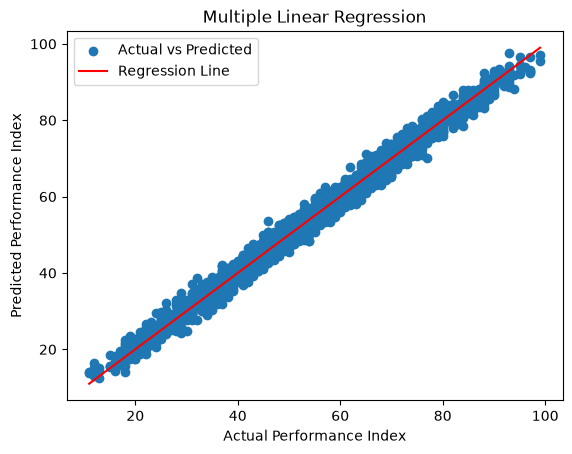

Predicted Performance Index: 91
Training RMSE: 2.041993107119857
Testing RMSE: 2.0205515085050054
Training R2: 0.9886898790682355
Testing R2: 0.9889832909573145
Accuracy: 96.5000734174015 %


In [ ]:

# Multiple Linear Regression

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Model training
model = LinearRegression()
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluation
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

# Visualization
plt.scatter(y_test, y_pred, label="Actual vs Predicted")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    label="Regression Line"
)

plt.xlabel("Actual Performance Index")
plt.ylabel("Predicted Performance Index")

plt.title("Multiple Linear Regression")

plt.legend()
plt.show()

# New prediction
new_data = pd.DataFrame({
    "Hours Studied": [10],
    "Previous Scores": [90],
    "Extracurricular Activities_Yes": [1],
    "Sleep Hours": [8],
    "Sample Question Papers Practiced": [7]
})

# Match the training feature order
new_data = new_data[X.columns]

prediction = model.predict(new_data)

print("Predicted Performance Index:",(prediction[0]))

# Training vs Testing Evaluation
train_pred = model.predict(X_train)

train_rmse = np.sqrt(
    mean_squared_error(y_train, train_pred)
)

test_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

train_r2 = r2_score(y_train, train_pred)

test_r2 = r2_score(y_test, y_pred)

print("Training RMSE:", train_rmse)
print("Testing RMSE:", test_rmse)

print("Training R2:", train_r2)
print("Testing R2:", test_r2)
accuracy = 100 - (abs(y_test - y_pred) / y_test * 100).mean()

print("Accuracy:", accuracy, "%")
